# 02. Sequential Multi-Agent 구현
**학습 목표:** Research Subgraph의 도구 사용, Agent 간 State 전달, 순차 실행, 출처 점검을 구현한다. `.env`의 `OPENAI_API_KEY`로 실제 LLM을 호출하고 `TAVILY_API_KEY`로 실시간 웹 검색을 호출하므로 실행마다 비용이 발생하며, 결과가 실행 시점의 웹 자료에 따라 달라질 수 있다.

## 1. 핵심 개념과 전체 아키텍처
상위 Graph는 **Research → Technology → Writer → Review** 순서를 고정한다. Research Agent 안에서는 **범위 결정 → 웹 검색**이 실행된다. 상위 순서와 내부 판단을 구분해 읽는다.

```mermaid
flowchart LR
  A[START] --> R[Research Subgraph]
  R --> T[Technology Analyst]
  T --> W[Report Writer]
  W --> V[Review Agent]
  V --> Z[END]
```

## 2. Import와 LLM 설정
`common.ai_model.get_llm_model()`은 `.env`의 `OPENAI_API_KEY`로 `ChatOpenAI`를 초기화한다. 모델명은 `.env`의 `LLM_MODEL` 값을 따른다(`.env.example`은 `gpt-4o-mini`).

In [1]:
from typing import TypedDict
from langgraph.graph import START, END, StateGraph

from common.ai_model import get_llm_model

llm_model = get_llm_model()

print(llm_model.model_name)

gpt-4o-mini


## 3. Tavily 웹 검색 도구
`TAVILY_API_KEY`로 `TavilyClient`를 초기화해 범주별 질의로 실제 웹 검색을 수행한다. 매 실행마다 최신 웹 자료를 가져오므로 결과(제목·URL·요지)가 실행 시점에 따라 달라질 수 있다.

In [2]:
from tavily import TavilyClient

from common.config import TAVILY_API_KEY

tavily_client = TavilyClient(api_key=TAVILY_API_KEY)

# 범주별 검색 질의: Research Agent가 고른 범주를 실제 웹 검색 질의로 변환한다.
CATEGORY_QUERIES = {
    "technology": "2026 AI 기술 동향 성능 벤치마크",
    "industry": "2026 AI 산업 도입 현황 기업 활용률",
    "governance": "AI 위험관리 프레임워크 거버넌스 규제",
}


def search_sources(categories: list[str]) -> list[dict]:
    """Research Agent가 선택한 범주에 대해 Tavily로 실제 웹 검색을 수행한다."""
    cards = []
    for category in categories:
        query = CATEGORY_QUERIES.get(category)
        if not query:
            continue
        response = tavily_client.search(query=query, max_results=2, search_depth="basic")
        for result in response.get("results", []):
            cards.append({
                "id": f"S{len(cards) + 1}",
                "category": category,
                "title": result.get("title", ""),
                "url": result.get("url", ""),
                # 요지는 검색 결과 본문 일부를 그대로 담는다(새로운 수치·사실을 만들지 않는다).
                "evidence": (result.get("content") or "")[:300],
            })
    return cards


def format_sources(cards: list[dict]) -> str:
    """LLM이 출처 ID와 근거를 함께 읽도록 간결하게 정리한다."""
    # 모델이 각 주장에 [S번호]를 그대로 인용할 수 있도록 ID를 맨 앞에 노출한다.
    return "\n".join(
        f'[{card["id"]}] {card["title"]}: {card["evidence"]} ({card["url"]})'
        for card in cards
    )

## 4. State 정의
`ReportState`는 상위 Agent 간 공유 계약이다. `ResearchState`는 Research Subgraph의 내부 계획을 추가로 보관한다.


In [3]:
class ReportState(TypedDict, total=False):
        user_request: str
        research_results: list[dict]
        technology_analysis: str
        final_report: str
        review_notes: str


## 5. Research Agent Subgraph
`StateGraph(ResearchState)`는 Agent의 내부 단계다. 컴파일된 Graph를 상위 Graph의 Node로 넣으면 공통 Key인 `user_request`, `research_results`가 전달된다.

In [4]:
class ResearchState(TypedDict, total=False):
    user_request: str
    research_scope: list[str]
    research_results: list[dict]


def decide_research_scope(state: ResearchState) -> dict:
    """요청을 보고 자료 조회 범위를 정한다."""
    # 판단 단계: 어떤 카테고리를 조회할지는 요청 내용에 따라 달라진다.
    scope = ["technology", "governance"]
    if "산업" in state["user_request"]:
        scope.append("industry")
    return {"research_scope": scope}


def retrieve_research(state: ResearchState) -> dict:
    """결정된 범위를 도구에 전달해 Tavily 웹 검색 결과를 가져온다."""
    # 실행 단계: 앞서 정한 범위로 웹 검색 도구를 그대로 호출한다(추가 판단 없음).
    return {"research_results": search_sources(state["research_scope"])}


# Research Agent 내부의 판단(decide_scope) → 도구 사용(web_search)을 별도 Subgraph로 표현한다.
research_builder = StateGraph(ResearchState)
research_builder.add_node("decide_scope", decide_research_scope)
research_builder.add_node("web_search", retrieve_research)
research_builder.add_edge(START, "decide_scope")
research_builder.add_edge("decide_scope", "web_search")
research_builder.add_edge("web_search", END)
# 컴파일된 Subgraph를 상위 Graph에는 하나의 Node처럼 등록한다.
research_agent = research_builder.compile()

## 6. Technology Analyst와 Report Writer
각 Agent는 입력 자료를 읽고 자신의 출력 Key만 반환한다. Writer는 근거 카드의 ID를 인용하도록 지시받는다.


In [5]:
def technology_agent(state: ReportState) -> dict:
        """Research 결과를 기술 분석으로 바꾼다."""
        prompt = (
            "당신은 AI 기술 분석가다. 제공 자료에서 확인되는 기술 동향과 한계를 "
            "2~3문장으로 설명하고 각 주장에 [S번호]를 붙여라. 자료 밖의 사실은 쓰지 마라.\n"
            f"요청: {state['user_request']}\n자료:\n{format_sources(state['research_results'])}"
        )
        return {"technology_analysis": llm_model.invoke(prompt).content}


def report_writer(state: ReportState) -> dict:
        """기술 분석을 Markdown 보고서로 정리한다."""
        prompt = (
            "당신은 보고서 작성자다. 제목, 핵심 분석, 한계, 참고자료를 포함한 짧은 "
            "Markdown 보고서를 작성하라. 주장 뒤에 [S번호]를 붙이고 자료 밖의 수치나 "
            "사례를 만들지 마라.\n"
            f"요청: {state['user_request']}\n분석: {state['technology_analysis']}\n"
            f"자료:\n{format_sources(state['research_results'])}"
        )
        return {"final_report": llm_model.invoke(prompt).content}


## 7. Review Agent
인용 ID의 존재는 코드로 확인한다. LLM은 제공된 자료와 주장 사이의 차이를 점검하지만, 최종 사실 확인은 원문 대조가 필요하다.


In [6]:
import re


def review_agent(state: ReportState) -> dict:
    """인용 ID를 기계적으로 검사하고 주장·근거 대조 의견을 구한다."""
    # 1) 코드로 하는 기계적 검사: 보고서의 [S번호]가 실제 자료 카드에 존재하는지만 확인한다.
    known_ids = {card["id"] for card in state["research_results"]}
    # known_ids만 순회해 포함 여부를 보면 보고서에만 있는 미등록(환각) 인용은 애초에 찾을 수 없으므로,
    # 보고서 텍스트에서 [S번호] 형태를 전부 추출한 뒤 known_ids와 차집합을 구해 미등록 ID를 가려낸다.
    cited_ids = set(re.findall(r"\[(S\d+)\]", state["final_report"]))
    unknown_ids = cited_ids - known_ids
    citation_check = (
        f"인용 ID {len(cited_ids)}개, 미등록 ID: {sorted(unknown_ids)}"
        if cited_ids else "인용 ID 없음: 출처 표기가 필요하다."
    )
    # 2) LLM이 하는 의미 판단: 주장이 자료 내용과 실제로 들어맞는지는 모델에 맡긴다.
    prompt = (
        "당신은 보고서 검토자다. 자료 카드와 보고서 주장을 비교해 "
        "'근거로 설명 가능', '자료로 판단 불가', '추가 확인 필요'로 구분하라. "
        "카드에 없는 수치·인과관계·일반화는 지적하라.\n"
        f"자료:\n{format_sources(state['research_results'])}\n"
        f"보고서:\n{state['final_report']}"
    )
    judgment = llm_model.invoke(prompt).content
    return {"review_notes": (
        f"{citation_check}\n\n{judgment}\n\n"
        "주의: 인용 ID 검사는 출처 존재만 확인한다. 주장과 원문의 일치는 사람이 최종 대조해야 한다."
    )}


## 8. 상위 Graph 구성과 Compile
`add_node`는 전문 Agent를 등록하고 `add_edge`는 순서를 정의한다. Research는 컴파일된 Subgraph이며 다른 세 Agent는 역할별 Node다.


In [7]:
builder = StateGraph(ReportState)
builder.add_node("research_agent", research_agent)
builder.add_node("technology_agent", technology_agent)
builder.add_node("report_writer", report_writer)
builder.add_node("review_agent", review_agent)

# 모든 Edge가 1:1로 이어지므로 네 Agent는 고정된 순서로만 실행된다(Sequential).
builder.add_edge(START, "research_agent")
builder.add_edge("research_agent", "technology_agent")
builder.add_edge("technology_agent", "report_writer")
builder.add_edge("report_writer", "review_agent")
builder.add_edge("review_agent", END)
graph = builder.compile()


## 9. Graph 시각화
PNG 생성이 실패하면 Mermaid 코드가 출력된다. 시각화 실패가 실습 실행을 막지 않는다.


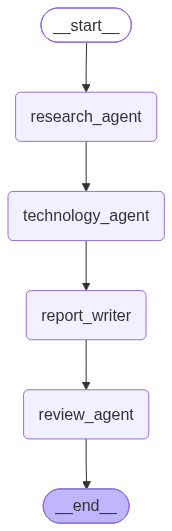

In [8]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception as exc:
    # 시각화 서비스가 없어도 Graph의 실행은 계속된다.
    print("PNG 시각화 불가:", type(exc).__name__)
    print(graph.get_graph().draw_mermaid())


## 10. 실행과 State 변화 확인
`stream(..., stream_mode="updates")`는 각 Node가 반환한 **부분 업데이트**를 보여 준다. 매 실행마다 네 Agent가 모두 LLM을 호출하므로 API 비용이 발생한다.


In [ ]:
initial_state = {"user_request": "AI 기술 동향과 위험 관리 관점을 분석한 보고서를 작성하라."}
final_state = dict(initial_state)

# stream(..., stream_mode="updates")는 각 Node가 반환한 변경분만 보여 주므로,
# 어떤 Agent가 State의 어떤 Key를 채웠는지 실행 순서대로 확인할 수 있다.
for update in graph.stream(initial_state, stream_mode="updates"):
    node_name, changed_values = next(iter(update.items()))
    final_state.update(changed_values)
    print(f"{node_name}: {list(changed_values)}")


# test: 최종 State에 모든 Key가 채워졌는지 확인한다.
assert final_state["research_results"]
assert final_state["technology_analysis"]
assert final_state["final_report"]
assert final_state["review_notes"]


research_agent: ['user_request', 'research_results']
technology_agent: ['technology_analysis']
report_writer: ['final_report']
review_agent: ['review_notes']


In [10]:
final_state

{'user_request': 'AI 기술 동향과 위험 관리 관점을 분석한 보고서를 작성하라.',
 'research_results': [{'id': 'S1',
   'category': 'technology',
   'title': '한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및...',
   'url': 'https://www.facebook.com/ITKOREANIA/posts/-the-ai-report-2026-1-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%85%8B-%ED%98%84%ED%99%A9-%EB%B6%84%EC%84%9D-%EB%B0%8F-%EC%A0%95%EB%B6%80-%EC%A3%BC%EB%8F%84%EC%9D%98-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%A7%88%EB%A0%A8-%ED%95%84%EC%9A%94%EC%84%B1-ai-%EC%84%B1%EB%8A%A5-%EB%AC%B4%EC%97%87%EC%9C%BC%EB%A1%9C-%EC%96%B4%EB%96%BB%EA%B2%8C-%ED%8F%89%EA%B0%80%ED%95%B4%EC%95%BC-%ED%95%A0/1224540443199953',
   'evidence': "## 한국지능정보사회진흥원's post\n\n### 한국지능정보사회진흥원\n\n28 January  ·\n\n📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및 정부 주도의 벤치마크 마련 필요성\n\n🤖📊 “AI 성능, 무엇으로 어떻게 평가해야 할까?”\n\n대규모 언어모델(LLM) 확산과 함께\n\nAI 모델 간 경쟁은 더욱 치열해지고 있지만,\n\n그 성능을 공정하고 신뢰성 있게 비교·검증할 수 있는 기준의 중요성도\n\n빠르게 커지고 있습니다.\n\n이번 리포트는\n\n국내외 AI 벤치마크 데이터셋 현황을 종합적으로 

## 11. 최종 결과
보고서와 검토 의견을 따로 제시한다. 출처 URL은 Tavily가 반환한 웹 검색 결과에서 확인한다.

In [11]:
from IPython.display import Markdown, display

display(Markdown(final_state["final_report"]))
display(Markdown("### 검토 의견\n" + final_state["review_notes"]))
print("자료 출처:")
for card in final_state["research_results"]:
    print(f"[{card['id']}] {card['title']} — {card['url']}")


# AI 기술 동향과 위험 관리 관점 분석 보고서

## 핵심 분석
AI 기술 동향은 대규모 언어모델(LLM)의 확산과 함께 AI 모델 간의 경쟁이 치열해지고 있으며, 이에 따라 성능을 공정하고 신뢰성 있게 비교·검증할 수 있는 기준의 필요성이 증가하고 있다[S1]. 그러나 현재 AI 벤치마크의 성과는 미비하여, 예를 들어 메타에서 제안한 ProgramBench에서는 모든 모델이 0% 달성률을 기록하는 등 기술적 한계가 드러났다[S2]. 또한, AI의 도입으로 인해 발생하는 다양한 위험 요소들, 예를 들어 사이버보안 및 데이터 프라이버시 문제는 여전히 많은 기업들이 해결해야 할 과제로 남아 있다[S3].

## 한계
현재 AI 기술의 발전 속도에 비해 벤치마크와 위험 관리 체계는 충분히 발전하지 못하고 있다. 특히, AI 모델의 성능을 평가하는 기준이 부족하여 신뢰할 수 있는 비교가 어렵고, 기업들이 AI 도입 시 직면하는 다양한 위험 요소에 대한 체계적인 관리가 미비하다. 이러한 한계는 AI 기술의 신뢰성과 안전성을 저해할 수 있다.

## 참고자료
- [S1] 한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및 정부 주도의 벤치마크 마련 필요성
- [S2] 인공지능 벤치마크 - 나무위키: AI의 프로그램 설계 및 제작 능력을 평가한다.
- [S3] AI 위험 관리 프레임워크: 거버넌스, 리스크, 규정 준수 | 인사이트리포트 | 삼성SDS

### 검토 의견
인용 ID 3개, 미등록 ID: []

보고서의 주장과 자료 카드를 비교하여 다음과 같이 구분하였습니다.

1. **근거로 설명 가능**
   - **주장**: AI 모델 간의 경쟁이 치열해지고 있으며, 성능을 공정하고 신뢰성 있게 비교·검증할 수 있는 기준의 필요성이 증가하고 있다.
     - **자료**: [S1]에서 AI 성능 평가 기준의 중요성을 언급하고 있음.
   - **주장**: ProgramBench에서 모든 모델이 0% 달성률을 기록하는 등 기술적 한계가 드러났다.
     - **자료**: [S2]에서 ProgramBench의 결과를 구체적으로 언급하고 있음.
   - **주장**: AI 도입으로 인해 발생하는 사이버보안 및 데이터 프라이버시 문제는 여전히 많은 기업들이 해결해야 할 과제로 남아 있다.
     - **자료**: [S3]에서 AI 도입 시 발생하는 위험 요소를 설명하고 있음.

2. **자료로 판단 불가**
   - **주장**: AI 벤치마크의 성과는 미비하다.
     - **자료**: [S2]에서 ProgramBench의 결과는 언급되지만, 전체 AI 벤치마크의 성과에 대한 구체적인 수치나 비교가 부족하여 판단하기 어려움.

3. **추가 확인 필요**
   - **주장**: AI 기술의 발전 속도에 비해 벤치마크와 위험 관리 체계는 충분히 발전하지 못하고 있다.
     - **자료**: 이 주장을 뒷받침할 수 있는 구체적인 수치나 사례가 부족하여 추가적인 확인이 필요함.
   - **주장**: AI 모델의 성능을 평가하는 기준이 부족하여 신뢰할 수 있는 비교가 어렵다.
     - **자료**: 이 주장에 대한 구체적인 예시나 데이터가 부족하여 추가적인 확인이 필요함.

**지적 사항**: 
- 보고서에서 언급된 "AI 벤치마크의 성과는 미비하다"는 주장은 구체적인 수치나 비교가 부족하여 판단하기 어렵습니다. 또한, "AI 기술의 발전 속도에 비해 벤치마크와 위험 관리 체계는 충분히 발전하지 못하고 있다"는 주장도 구체적인 근거

주의: 인용 ID 검사는 출처 존재만 확인한다. 주장과 원문의 일치는 사람이 최종 대조해야 한다.

자료 출처:
[S1] 한국지능정보사회진흥원 - 📢 [The AI Report 2026-1] 벤치마크 데이터셋 현황 분석 및... — https://www.facebook.com/ITKOREANIA/posts/-the-ai-report-2026-1-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%8D%B0%EC%9D%B4%ED%84%B0%EC%85%8B-%ED%98%84%ED%99%A9-%EB%B6%84%EC%84%9D-%EB%B0%8F-%EC%A0%95%EB%B6%80-%EC%A3%BC%EB%8F%84%EC%9D%98-%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC-%EB%A7%88%EB%A0%A8-%ED%95%84%EC%9A%94%EC%84%B1-ai-%EC%84%B1%EB%8A%A5-%EB%AC%B4%EC%97%87%EC%9C%BC%EB%A1%9C-%EC%96%B4%EB%96%BB%EA%B2%8C-%ED%8F%89%EA%B0%80%ED%95%B4%EC%95%BC-%ED%95%A0/1224540443199953
[S2] 인공지능 벤치마크 - 나무위키 — https://namu.wiki/w/%EC%9D%B8%EA%B3%B5%EC%A7%80%EB%8A%A5%20%EB%B2%A4%EC%B9%98%EB%A7%88%ED%81%AC
[S3] AI 위험 관리 프레임워크: 거버넌스, 리스크, 규정 준수 | 인사이트리포트 | 삼성SDS — https://www.samsungsds.com/kr/insights/ai-risk-management-framework.html
[S4] AI 규제 프레임워크 | FlowHunt — https://www.flowhunt.io/ko/%EC%9A%A9%EC%96%B4%EC%A7%91/ai-regulatory-frameworks


## 12. 핵심 개념 정리와 수강생 미션
Research의 판단·도구 사용은 내부 Subgraph에서 일어나고, 상위 Graph는 전문 Agent들의 협업 순서를 관리한다. Agent는 맡은 State Key만 반환한다.

**미션:** Review Agent가 개선 사항을 `review_notes`에 2개 이상 제안하도록 프롬프트를 바꾼다. 인용 ID가 빠진 보고서를 넣어 경고가 출력되는지도 확인한다.
